# Entraînement 2-8-8-1 — Disque — Simulated Annealing
Equivalent Python du document 8 adapté pour l'architecture 2→8→8→1.  
**Dataset** : 400 points aléatoires autour du disque r=0.5  
**Algorithme** : Simulated Annealing — accepte des dégradations temporaires → sort des minima locaux  
**Candidats** : EXC [0.135…3.000] µm, INH [0.135…0.700] µm (limité comme dans Cadence)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
print("Imports OK")


Imports OK


In [2]:
# ── Paramètres globaux ──────────────────────────────────────
INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'

N_TRAIN      = 400
N_TEST       = 200
DISK_RADIUS  = 0.5
MARGIN_EXCL  = 0.05

N_RESTARTS   = 8
N_ITER_SA    = 3000
TEMP_START   = 0.08
TEMP_END     = 1e-4

MIN_MARGIN_HZ      = 500.0
MIN_MARGIN_PENALTY = 0.1
MARGIN_SCALE       = 1e-5

SEED = 42
print("Config OK")


Config OK


In [3]:
# ── Chargement CSV ───────────────────────────────────────────
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    data_cols = [c for c in df.columns if c not in ['Parameter','Unnamed: 1']]
    def get_row(name):
        row = df.loc[df['Parameter']==name, data_cols]
        if row.empty: raise ValueError(f"'{name}' introuvable")
        return pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
    return get_row

inp = read_cadence_rows(INPUT_CSV)
INPUT_V_AXIS = inp('Vex');    INPUT_F_AXIS = inp('Fspikes')

neu = read_cadence_rows(NEURON_CSV)
NEURON_I_AXIS = neu('Iex');   NEURON_F_AXIS = neu('Fspikes')

exc = read_cadence_rows(SYN_EXC_CSV)
EXC_W2=exc('W2'); EXC_FPRE=exc('Fpre'); EXC_IPOST=exc('Ipost')

inh = read_cadence_rows(SYN_INH_CSV)
INH_W2=inh('W2'); INH_FPRE=inh('Fpre'); INH_IPOST=inh('Ipost')

def build_grid(W,F,Y):
    Wu=np.unique(W); Fu=np.unique(F)
    g=np.full((len(Wu),len(Fu)),np.nan)
    for i,w in enumerate(Wu):
        for j,f in enumerate(Fu):
            m=np.isclose(W,w)&np.isclose(F,f)
            if m.any(): g[i,j]=np.mean(Y[m])
    return Wu,Fu,g

def interp2(w,f,Wa,Fa,G):
    w=np.clip(w,Wa[0],Wa[-1]); f=np.clip(f,Fa[0],Fa[-1])
    wi=min(np.searchsorted(Wa,w,'right')-1,len(Wa)-2)
    fi=min(np.searchsorted(Fa,f,'right')-1,len(Fa)-2)
    tx=(w-Wa[wi])/(Wa[wi+1]-Wa[wi]) if Wa[wi+1]!=Wa[wi] else 0.
    ty=(f-Fa[fi])/(Fa[fi+1]-Fa[fi]) if Fa[fi+1]!=Fa[fi] else 0.
    return (G[wi,fi]*(1-tx)*(1-ty)+G[wi+1,fi]*tx*(1-ty)+
            G[wi,fi+1]*(1-tx)*ty  +G[wi+1,fi+1]*tx*ty)

EXC_WA,EXC_FA,EXC_GRID = build_grid(EXC_W2,EXC_FPRE,EXC_IPOST)
INH_WA,INH_FA,INH_GRID = build_grid(INH_W2,INH_FPRE,INH_IPOST)

print(f"Input  : [{INPUT_V_AXIS[0]*1e3:.0f},{INPUT_V_AXIS[-1]*1e3:.0f}]mV "
      f"→ [{INPUT_F_AXIS[0]/1e3:.1f},{INPUT_F_AXIS[-1]/1e3:.1f}]kHz")
print(f"Neuron : [{NEURON_I_AXIS[0]*1e12:.0f},{NEURON_I_AXIS[-1]*1e12:.0f}]pA "
      f"→ [{NEURON_F_AXIS[0]/1e3:.1f},{NEURON_F_AXIS[-1]/1e3:.1f}]kHz")
print(f"EXC grid {len(EXC_WA)}x{len(EXC_FA)} | INH grid {len(INH_WA)}x{len(INH_FA)}")


Input  : [-100,100]mV → [1.1,56.0]kHz
Neuron : [3,1000]pA → [3.1,193.1]kHz
EXC grid 20x12 | INH grid 20x10


In [4]:
# ── Topologie 2→8→8→1 ───────────────────────────────────────
W_MIN = 0.135

# Candidats discrets — INH limité à 0.700 max
EXC_CANDIDATES = [0.135,0.270,0.405,0.540,0.675,0.810,
                  1.080,1.350,1.620,2.000,2.500,3.000]
INH_CANDIDATES = [0.135,0.270,0.405,0.540,0.675,0.700]

# Tous les états possibles d'une synapse : (signe, valeur)
# +1=EXC, -1=INH
ALL_STATES = ([(+1,w) for w in EXC_CANDIDATES]
             +[(-1,w) for w in INH_CANDIDATES if w>W_MIN])

N_C1=8; N_C2=8; N_OUT=1

SYNAPSES=[]
for i in range(1,N_C1+1):
    SYNAPSES.append(("Vx_c1",f"Vx_c1_e1{i}",f"Vx_c1_i1{i}"))
for i in range(1,N_C1+1):
    SYNAPSES.append(("Vy_c1",f"Vy_c1_e2{i}",f"Vy_c1_i2{i}"))
for i in range(1,N_C1+1):
    for j in range(1,N_C2+1):
        SYNAPSES.append(("c1_c2",f"c1_c2_e{i}{j}",f"c1_c2_i{i}{j}"))
for i in range(1,N_C2+1):
    SYNAPSES.append(("c2_s",f"c2_s_e{i}1",f"c2_s_i{i}1"))

N_SYN = len(SYNAPSES)
# Représentation compacte : tableau d'états (index dans ALL_STATES)
print(f"Synapses : {N_SYN}")
print(f"États/synapse : {len(ALL_STATES)} ({len(EXC_CANDIDATES)} EXC + {len(INH_CANDIDATES)-1} INH)")
print(f"Espace de recherche : ~{len(ALL_STATES)**N_SYN:.2e}")


Synapses : 88
États/synapse : 17 (12 EXC + 5 INH)
Espace de recherche : ~1.90e+108


In [5]:
# ── Poids → simulation ──────────────────────────────────────
def states_to_weights(states):
    """Tableau d'états (N_SYN ints) → dict poids."""
    w = {k: W_MIN for s in SYNAPSES for k in (s[1],s[2])}
    for si,(sn,en,in_) in enumerate(SYNAPSES):
        sg,val = ALL_STATES[states[si]]
        if sg==+1: w[en]=val; w[in_]=W_MIN
        else:      w[en]=W_MIN; w[in_]=val
    return w

def v_to_freq(v_mv):
    return float(np.interp(v_mv/1000., INPUT_V_AXIS, INPUT_F_AXIS))

def i_to_freq(i_a):
    return float(np.interp(max(0.,i_a), NEURON_I_AXIS, NEURON_F_AXIS))

def syn_i(sg, w_um, fpre):
    if sg==+1: return  interp2(w_um,fpre,EXC_WA,EXC_FA,EXC_GRID)
    else:      return -abs(interp2(w_um,fpre,INH_WA,INH_FA,INH_GRID))

def forward_states(vx_mv, vy_mv, states):
    fx=v_to_freq(vx_mv); fy=v_to_freq(vy_mv)
    # C1
    i_c1=np.zeros(N_C1)
    for i in range(N_C1):
        sg_x,w_x=ALL_STATES[states[i]]
        sg_y,w_y=ALL_STATES[states[N_C1+i]]
        i_c1[i]=syn_i(sg_x,w_x,fx)+syn_i(sg_y,w_y,fy)
    f_c1=np.array([i_to_freq(ic) for ic in i_c1])
    # C2
    i_c2=np.zeros(N_C2)
    base=2*N_C1
    for j in range(N_C2):
        for i in range(N_C1):
            sg,w=ALL_STATES[states[base+i*N_C2+j]]
            i_c2[j]+=syn_i(sg,w,f_c1[i])
    f_c2=np.array([i_to_freq(ic) for ic in i_c2])
    # Sortie
    i_out=0.
    base2=base+N_C1*N_C2
    for i in range(N_C2):
        sg,w=ALL_STATES[states[base2+i]]
        i_out+=syn_i(sg,w,f_c2[i])
    return i_to_freq(i_out)

def forward_batch(V, states):
    """V : (N,2) en mV → array fréquences Hz."""
    return np.array([forward_states(vx,vy,states) for vx,vy in V])

# Test rapide
s0=np.zeros(N_SYN,dtype=int)  # tous EXC à W_MIN
print("Test W_MIN:")
for vx,vy in [(15,0),(85,0),(-15,0),(-85,0)]:
    print(f"  ({vx:>4},{vy:>3}) → {forward_states(vx,vy,s0)/1e3:.2f} kHz")


Test W_MIN:
  (  15,  0) → 3.08 kHz
  (  85,  0) → 3.08 kHz
  ( -15,  0) → 3.08 kHz
  ( -85,  0) → 3.08 kHz


Train : 400 pts — int=68 (17%) ext=332


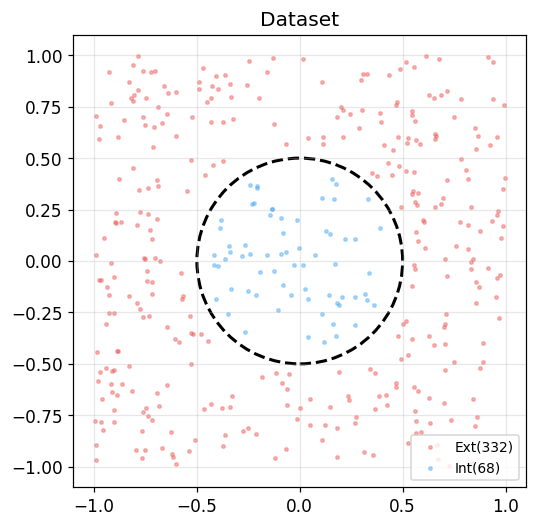

In [6]:
# ── Dataset ─────────────────────────────────────────────────
def make_dataset(n, seed=0):
    rng2=np.random.default_rng(seed); pts=[]
    while len(pts)<n:
        b=rng2.uniform(-1,1,(n*3,2))
        ok=np.abs(np.sqrt((b**2).sum(1))-DISK_RADIUS)>MARGIN_EXCL
        pts.extend(b[ok].tolist())
    return np.array(pts[:n])

def xy_to_vmv(X):
    """(N,2) coords [-1,1] → (N,2) tensions mV."""
    return (-0.1+(X+1)*0.1)*1e3

def label(X):
    return ((X[:,0]**2+X[:,1]**2)<DISK_RADIUS**2).astype(int)

X_tr=make_dataset(N_TRAIN,SEED);   y_tr=label(X_tr)
X_te=make_dataset(N_TEST, SEED+1); y_te=label(X_te)
V_tr=xy_to_vmv(X_tr); V_te=xy_to_vmv(X_te)

n1=y_tr.sum(); n0=(1-y_tr).sum()
print(f"Train : {N_TRAIN} pts — int={n1} ({100*n1/N_TRAIN:.0f}%) ext={n0}")

fig,ax=plt.subplots(figsize=(5,5))
ax.scatter(X_tr[y_tr==0,0],X_tr[y_tr==0,1],s=5,alpha=0.4,c='#EF5350',label=f'Ext({n0})')
ax.scatter(X_tr[y_tr==1,0],X_tr[y_tr==1,1],s=5,alpha=0.4,c='#42A5F5',label=f'Int({n1})')
ax.add_patch(plt.Circle((0,0),DISK_RADIUS,color='k',fill=False,lw=2,ls='--'))
ax.set_aspect('equal'); ax.set_xlim(-1.1,1.1); ax.set_ylim(-1.1,1.1)
ax.legend(fontsize=9); ax.grid(True,alpha=0.3); ax.set_title('Dataset')
plt.tight_layout(); plt.show()


In [7]:
# ── Score (comme document 8) ─────────────────────────────────
def find_thr(Fout, y, n=50):
    f0,f1=float(Fout.min()),float(Fout.max())
    if f1<=f0: return (f0+f1)/2, 0.5
    cands=np.linspace(f0,f1,n+2)[1:-1]
    bt,ba=cands[0],-1.
    for t in cands:
        p=(Fout>=t).astype(int)
        m0,m1=y==0,y==1
        a=.5*((np.mean(p[m0]==0) if m0.any() else 0.)
             +(np.mean(p[m1]==1) if m1.any() else 0.))
        if a>ba: ba,bt=a,t
    return bt,ba

def score_fn(Fout, y, thr=None):
    if thr is None: thr,_=find_thr(Fout,y)
    m0,m1=y==0,y==1
    p=(Fout>=thr).astype(int)
    a0=float(np.mean(p[m0]==0)) if m0.any() else 0.
    a1=float(np.mean(p[m1]==1)) if m1.any() else 0.
    bal=.5*(a0+a1)
    marg=np.where(y==1,Fout-thr,thr-Fout)
    fl=float(np.mean(marg<MIN_MARGIN_HZ))
    sc=bal - MIN_MARGIN_PENALTY*fl + MARGIN_SCALE*float(np.mean(marg))
    return sc,{'bal_acc':bal,'acc0':a0,'acc1':a1,'frac_below':fl},thr


In [8]:
# ── Simulated Annealing ──────────────────────────────────────
ALL_CONNS = list(range(N_SYN))  # indices de toutes les connexions

def sa_run(restart_idx, rng_seed):
    rng=np.random.default_rng(rng_seed); R=f'R{restart_idx+1:02d}'

    # Init aléatoire
    states=rng.integers(0,len(ALL_STATES),N_SYN)
    Fout=forward_batch(V_tr,states)
    sc,m,thr=score_fn(Fout,y_tr)

    best_states=states.copy(); best_sc=sc; best_thr=thr
    temps=TEMP_START*(TEMP_END/TEMP_START)**(np.arange(N_ITER_SA)/(N_ITER_SA-1))

    log_every=max(1,N_ITER_SA//10); history=[]; n_acc=0
    t0=time.time()

    for it in range(N_ITER_SA):
        T=temps[it]
        # Mutation : change une synapse aléatoire
        si=int(rng.integers(N_SYN))
        orig=int(states[si])
        states[si]=int(rng.integers(len(ALL_STATES)))

        Fout_new=forward_batch(V_tr,states)
        new_sc,new_m,new_thr=score_fn(Fout_new,y_tr)
        delta=new_sc-sc

        if delta>0 or rng.random()<np.exp(delta/T):
            sc,m,thr=new_sc,new_m,new_thr; Fout=Fout_new; n_acc+=1
            if sc>best_sc:
                best_sc=sc; best_thr=thr; best_states=states.copy()
        else:
            states[si]=orig

        if it%log_every==0 or it==N_ITER_SA-1:
            history.append({'iter':it,'T':T,'score':sc,
                            'bal_acc':m['bal_acc'],'best_sc':best_sc})

    elapsed=time.time()-t0
    # Eval finale
    Fo_tr=forward_batch(V_tr,best_states)
    Fo_te=forward_batch(V_te,best_states)
    sc_tr,m_tr,thr_tr=score_fn(Fo_tr,y_tr)
    sc_va,m_va,_    =score_fn(Fo_te,y_te,thr=thr_tr)

    print(f"  {R} | tr={m_tr['bal_acc']:.3f} va={m_va['bal_acc']:.3f} | "
          f"acc={n_acc/N_ITER_SA*100:.0f}% | {elapsed:.0f}s")
    return {'states':best_states,'threshold':thr_tr,
            'tr_bal_acc':m_tr['bal_acc'],'va_bal_acc':m_va['bal_acc'],
            'tr_score':sc_tr,'va_score':sc_va,'history':history,
            'Fo_tr':Fo_tr,'Fo_te':Fo_te}

seeds=[SEED+r*1000 for r in range(N_RESTARTS)]
print(f"SA : {N_RESTARTS} restarts × {N_ITER_SA} itérations")
print(f"Température : {TEMP_START} → {TEMP_END}")
print(f"Estimation : ~{N_ITER_SA*N_SYN*1e-6:.1f}M évaluations synapse")
t0=time.time()
results=[sa_run(r,seeds[r]) for r in range(N_RESTARTS)]
best=max(results,key=lambda r:(r['va_bal_acc'],r['va_score']))
print(f"\n★ BEST  va={best['va_bal_acc']:.4f}  tr={best['tr_bal_acc']:.4f}  "
      f"seuil={best['threshold']/1e3:.2f}kHz  "
      f"temps total={time.time()-t0:.0f}s")


SA : 8 restarts × 3000 itérations
Température : 0.08 → 0.0001
Estimation : ~0.3M évaluations synapse
  R01 | tr=0.757 va=0.775 | acc=95% | 812s
  R02 | tr=0.618 va=0.650 | acc=92% | 809s
  R03 | tr=0.498 va=0.500 | acc=81% | 804s
  R04 | tr=0.500 va=0.500 | acc=100% | 810s
  R05 | tr=0.497 va=0.500 | acc=92% | 797s
  R06 | tr=0.498 va=0.500 | acc=92% | 794s
  R07 | tr=0.739 va=0.772 | acc=85% | 794s
  R08 | tr=0.618 va=0.650 | acc=87% | 795s

★ BEST  va=0.7750  tr=0.7574  seuil=6.81kHz  temps total=6419s


In [9]:
# ── Résultats ────────────────────────────────────────────────
thr=best['threshold']
Fo_tr=best['Fo_tr']; Fo_te=best['Fo_te']
_,m_tr,_=score_fn(Fo_tr,y_tr,thr=thr)
_,m_va,_=score_fn(Fo_te,y_te,thr=thr)

print(f"TRAIN  bal_acc={m_tr['bal_acc']:.4f}  acc0={m_tr['acc0']:.4f}  acc1={m_tr['acc1']:.4f}")
print(f"TEST   bal_acc={m_va['bal_acc']:.4f}  acc0={m_va['acc0']:.4f}  acc1={m_va['acc1']:.4f}")
print(f"Seuil  {thr/1e3:.3f} kHz")
print(f"Fout range train : [{Fo_tr.min()/1e3:.1f}, {Fo_tr.max()/1e3:.1f}] kHz")


TRAIN  bal_acc=0.7574  acc0=1.0000  acc1=0.5147
TEST   bal_acc=0.7750  acc0=1.0000  acc1=0.5500
Seuil  6.809 kHz
Fout range train : [3.1, 193.1] kHz


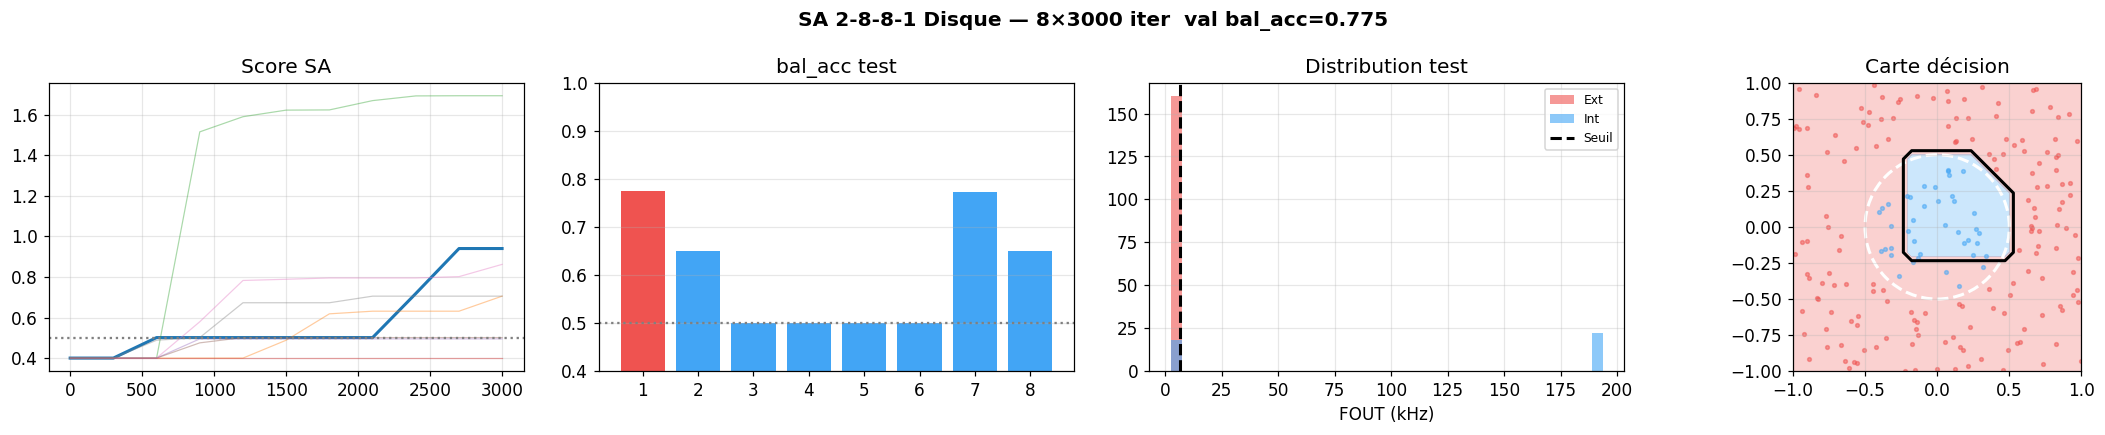

In [10]:
# ── Courbes SA + carte de décision ──────────────────────────
fig,axes=plt.subplots(1,4,figsize=(20,4))
fig.suptitle(f'SA 2-8-8-1 Disque — {N_RESTARTS}×{N_ITER_SA} iter  '
             f'val bal_acc={best["va_bal_acc"]:.3f}',fontweight='bold')

# Courbes score
ax=axes[0]
for r in results:
    h=r['history']; iters=[x['iter'] for x in h]
    ax.plot(iters,[x['best_sc'] for x in h],
            lw=2 if r is best else 0.8,
            alpha=1. if r is best else 0.4)
ax.axhline(0.5,color='gray',ls=':'); ax.set_title('Score SA'); ax.grid(True,alpha=0.3)

# bal_acc par restart
ax=axes[1]
va=[r['va_bal_acc'] for r in results]
ax.bar(range(1,N_RESTARTS+1),va,
       color=['#EF5350' if r is best else '#42A5F5' for r in results])
ax.axhline(0.5,color='gray',ls=':'); ax.set_title('bal_acc test')
ax.set_ylim(0.4,1.); ax.grid(True,alpha=0.3,axis='y')

# Distribution Fout
ax=axes[2]
bins=np.linspace(min(Fo_te)-500,max(Fo_te)+500,40)
ax.hist(Fo_te[y_te==0]/1e3,bins=bins/1e3,alpha=0.6,color='#EF5350',label='Ext')
ax.hist(Fo_te[y_te==1]/1e3,bins=bins/1e3,alpha=0.6,color='#42A5F5',label='Int')
ax.axvline(thr/1e3,color='k',lw=2,ls='--',label=f'Seuil')
ax.set_xlabel('FOUT (kHz)'); ax.set_title('Distribution test')
ax.legend(fontsize=8); ax.grid(True,alpha=0.3)

# Carte de décision
ax=axes[3]
res=35; xs=np.linspace(-1,1,res); XX,YY=np.meshgrid(xs,xs)
pts=np.column_stack([XX.ravel(),YY.ravel()])
Vg=xy_to_vmv(pts)
FG=forward_batch(Vg,best['states']).reshape(XX.shape)
ax.contourf(XX,YY,(FG>thr).astype(int),levels=[-0.5,.5,1.5],
            colors=['#EF535044','#42A5F544'])
ax.contour(XX,YY,FG-thr,levels=[0],colors='k',linewidths=2)
ax.add_patch(plt.Circle((0,0),DISK_RADIUS,color='white',fill=False,lw=2,ls='--'))
ax.scatter(X_te[y_te==0,0],X_te[y_te==0,1],s=6,c='#EF5350',alpha=0.5)
ax.scatter(X_te[y_te==1,0],X_te[y_te==1,1],s=6,c='#42A5F5',alpha=0.5)
ax.set_title('Carte décision'); ax.set_aspect('equal'); ax.grid(True,alpha=0.3)

plt.tight_layout(); plt.show()


In [11]:
# ── Export poids ─────────────────────────────────────────────
rows=[]
for si,(sn,en,in_) in enumerate(SYNAPSES):
    sg,val=ALL_STATES[best['states'][si]]
    rows.append({'synapse':sn,'e_param':en,'i_param':in_,
                 'sign':int(sg),'width_um':float(val),
                 'type':'EXC' if sg==+1 else 'INH'})

df_w=pd.DataFrame(rows)
df_w.to_csv('weights_disk_sa.csv',index=False)
pd.DataFrame([{'threshold_Hz':thr,'threshold_kHz':thr/1e3,
               'bal_acc_train':m_tr['bal_acc'],
               'bal_acc_test':m_va['bal_acc']}]
             ).to_csv('threshold_disk_sa.csv',index=False)

print("Exporté → weights_disk_sa.csv + threshold_disk_sa.csv")
print(f"Synapses non-MIN : {(df_w['type']!='MIN').sum()} / {len(df_w)}")
print()
# Affichage par groupe
for grp in ['Vx_c1','Vy_c1','c2_s']:
    sub=df_w[df_w['synapse']==grp]
    print(f"[{grp}]")
    for _,row in sub.iterrows():
        print(f"  {row['e_param']:20s} → {row['type']}({row['width_um']:.3f}µm)")


Exporté → weights_disk_sa.csv + threshold_disk_sa.csv
Synapses non-MIN : 88 / 88

[Vx_c1]
  Vx_c1_e11            → EXC(0.810µm)
  Vx_c1_e12            → EXC(1.080µm)
  Vx_c1_e13            → INH(0.540µm)
  Vx_c1_e14            → EXC(0.540µm)
  Vx_c1_e15            → INH(0.270µm)
  Vx_c1_e16            → EXC(1.620µm)
  Vx_c1_e17            → INH(0.405µm)
  Vx_c1_e18            → EXC(3.000µm)
[Vy_c1]
  Vy_c1_e21            → EXC(0.810µm)
  Vy_c1_e22            → EXC(3.000µm)
  Vy_c1_e23            → EXC(1.620µm)
  Vy_c1_e24            → INH(0.540µm)
  Vy_c1_e25            → EXC(1.080µm)
  Vy_c1_e26            → INH(0.540µm)
  Vy_c1_e27            → EXC(0.810µm)
  Vy_c1_e28            → EXC(1.620µm)
[c2_s]
  c2_s_e11             → INH(0.675µm)
  c2_s_e21             → INH(0.675µm)
  c2_s_e31             → INH(0.405µm)
  c2_s_e41             → INH(0.540µm)
  c2_s_e51             → EXC(1.350µm)
  c2_s_e61             → INH(0.270µm)
  c2_s_e71             → INH(0.270µm)
  c2_s_e81           